In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [6]:
import sys
sys.path.append("src")

from signal_generation import generate_bpsk, generate_qpsk, generate_16qam

print("Signal generation functions imported successfully!")

BPSK generated: 1000
QPSK generated: 1000
16-QAM generated: 1000
Signal generation functions imported successfully!


In [2]:
def generate_awgn(n_samples, noise_power):

    noise = np.sqrt(noise_power / 2) * (
        np.random.randn(n_samples)
        + 1j * np.random.randn(n_samples)
    )

    return noise

In [3]:
def add_awgn(signal, snr_db):

    signal_power = np.mean(np.abs(signal)**2)

    snr_linear = 10**(snr_db / 10)

    noise_power = signal_power / snr_linear

    noise = generate_awgn(
        len(signal),
        noise_power
    )

    received_signal = signal + noise

    return received_signal, noise

In [4]:
def calculate_snr(original, noise):

    signal_power = np.mean(np.abs(original)**2)

    noise_power = np.mean(np.abs(noise)**2)

    snr = 10 * np.log10(
        signal_power / noise_power
    )

    return snr

In [7]:
qpsk = generate_qpsk(10000)

snr_values = [-20, -15, -10, -5, 0, 5, 10]

for snr in snr_values:

    received, noise = add_awgn(qpsk, snr)

    measured_snr = calculate_snr(
        qpsk,
        noise
    )

    print(
        f"Target SNR: {snr:>3} dB | "
        f"Measured SNR: {measured_snr:.2f} dB"
    )

Target SNR: -20 dB | Measured SNR: -19.96 dB
Target SNR: -15 dB | Measured SNR: -15.02 dB
Target SNR: -10 dB | Measured SNR: -10.01 dB
Target SNR:  -5 dB | Measured SNR: -5.02 dB
Target SNR:   0 dB | Measured SNR: 0.02 dB
Target SNR:   5 dB | Measured SNR: 5.00 dB
Target SNR:  10 dB | Measured SNR: 9.99 dB


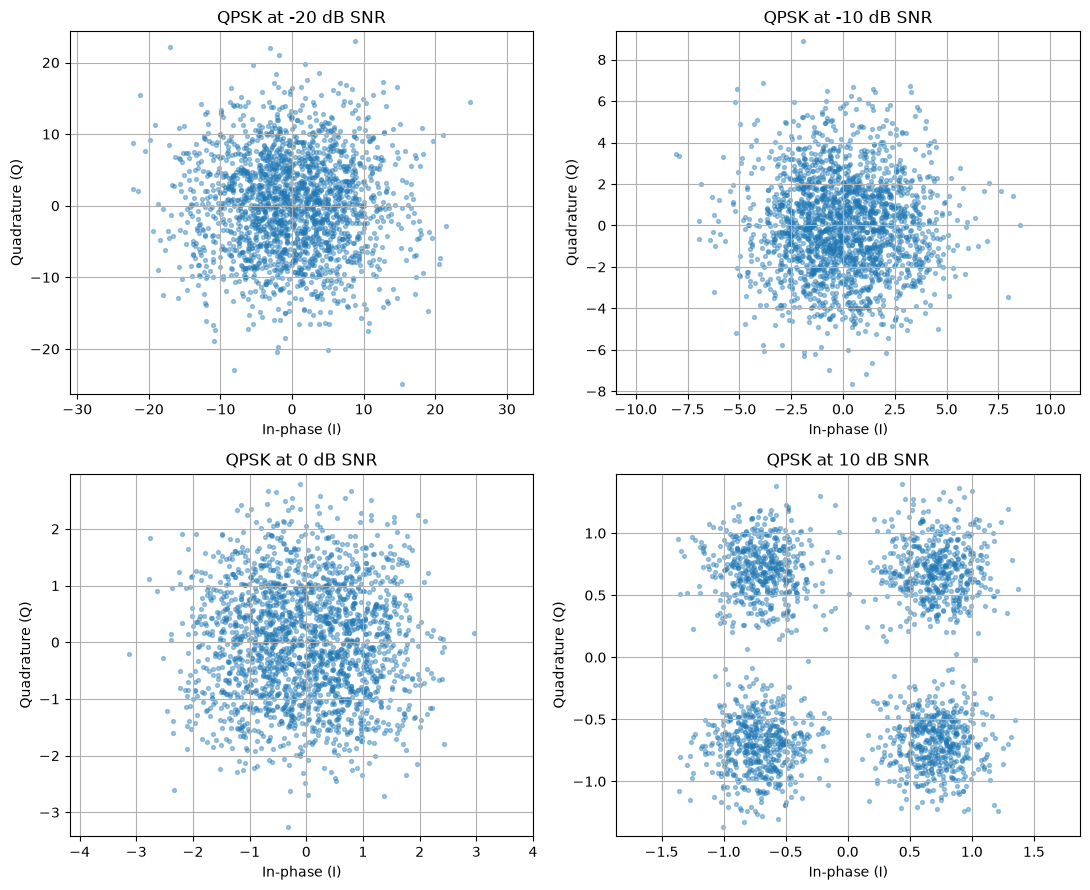

In [8]:
qpsk = generate_qpsk(2000)

snr_values = [-20, -10, 0, 10]

fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 9)
)

for ax, snr in zip(axes.flat, snr_values):

    received, noise = add_awgn(
        qpsk,
        snr
    )

    ax.scatter(
        received.real,
        received.imag,
        s=8,
        alpha=0.4
    )

    ax.set_title(f"QPSK at {snr} dB SNR")
    ax.set_xlabel("In-phase (I)")
    ax.set_ylabel("Quadrature (Q)")
    ax.grid(True)
    ax.axis("equal")

plt.tight_layout()
plt.show()

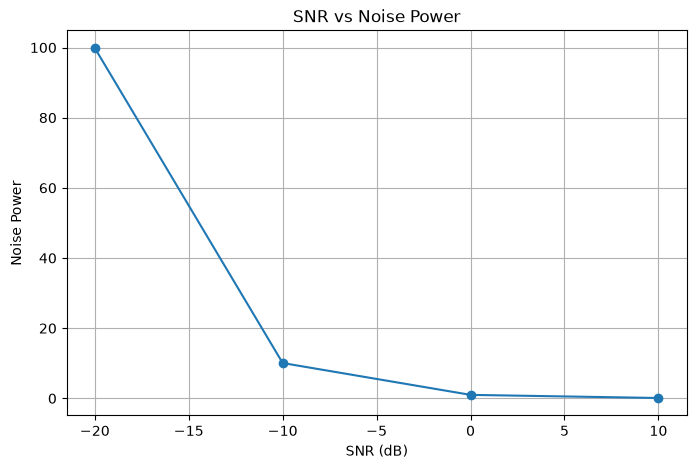

In [9]:
qpsk = generate_qpsk(10000)

noise_powers = []

for snr in snr_values:

    received, noise = add_awgn(qpsk, snr)

    noise_powers.append(
        np.mean(np.abs(noise)**2)
    )

plt.figure(figsize=(8, 5))

plt.plot(
    snr_values,
    noise_powers,
    marker="o"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Noise Power")
plt.title("SNR vs Noise Power")

plt.grid(True)
plt.show()